# 02 滤波与 STFT 时频分析

本 Notebook 演示：

1. 带通滤波和空间共模噪声去除；
2. 滤波前后瀑布图对比；
3. 单通道 STFT 频谱；
4. 小波包频带能量特征。

参数全部来自 `configs/exp_default.yaml`。


In [1]:
%matplotlib inline

from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import yaml

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dsp import (
    bandpass_filter,
    spatial_common_mode_removal,
    stft_feature,
    wavelet_packet_features,
)
from src.utils import plot_spectrogram, plot_waterfall

config = yaml.safe_load(
    (PROJECT_ROOT / "configs" / "exp_default.yaml").read_text(encoding="utf-8")
)
DATA_DIR = PROJECT_ROOT / "data"


def load_example_recording():
    h5_files = []
    for pattern in ("*.h5", "*.hdf5", "*.H5", "*.HDF5"):
        h5_files.extend(sorted((DATA_DIR / "raw").rglob(pattern)))
    if h5_files:
        from src.data_io import HDF5DASReader

        reader = HDF5DASReader(h5_files[0], orientation="auto")
        return reader.read(dtype="float32"), reader.metadata.to_dict(), h5_files[0]

    for folder in ("synthetic", "processed"):
        files = sorted((DATA_DIR / folder).rglob("*.npz"))
        if files:
            with np.load(files[0], allow_pickle=False) as payload:
                data = np.asarray(payload["data"], dtype=np.float32)
                metadata = {}
                if "metadata" in payload:
                    try:
                        metadata = json.loads(str(payload["metadata"]))
                    except json.JSONDecodeError:
                        metadata = {}
                if "sampling_rate_hz" in payload:
                    metadata["sampling_rate_hz"] = float(payload["sampling_rate_hz"][0])
                if "channel_spacing_m" in payload:
                    metadata["channel_spacing_m"] = float(payload["channel_spacing_m"][0])
                return data, metadata, files[0]
    raise FileNotFoundError("请先运行 scripts/run_preprocess.py --synthetic --overwrite")


recording, metadata, source_path = load_example_recording()
sampling_rate_hz = float(
    metadata.get("sampling_rate_hz", config["data"]["sampling_rate_hz"])
)
channel_spacing_m = float(
    metadata.get("channel_spacing_m", config["data"]["spatial_spacing_m"])
)
print("Loaded:", source_path, recording.shape)


Loaded: D:\DSwork\DAS_Track_Anomaly_Detection\data\synthetic\test\test_anomaly_0000.npz (96, 8000)


## 1. 时域滤波与空间共模去除


In [2]:
bandpass_hz = config["data"]["bandpass_hz"]
filtered = bandpass_filter(
    recording,
    sampling_rate_hz=sampling_rate_hz,
    low_hz=bandpass_hz[0],
    high_hz=bandpass_hz[1],
    order=int(config["data"]["filter_order"]),
)
cleaned = spatial_common_mode_removal(
    filtered,
    window=int(config["data"]["common_mode_window"]),
    axis=0,
    method="median",
)
print("Input RMS:", float(np.sqrt(np.mean(recording ** 2))))
print("Filtered RMS:", float(np.sqrt(np.mean(filtered ** 2))))
print("Cleaned RMS:", float(np.sqrt(np.mean(cleaned ** 2))))


Input RMS: 0.14882853627204895
Filtered RMS: 0.14352183043956757
Cleaned RMS: 0.013966693542897701


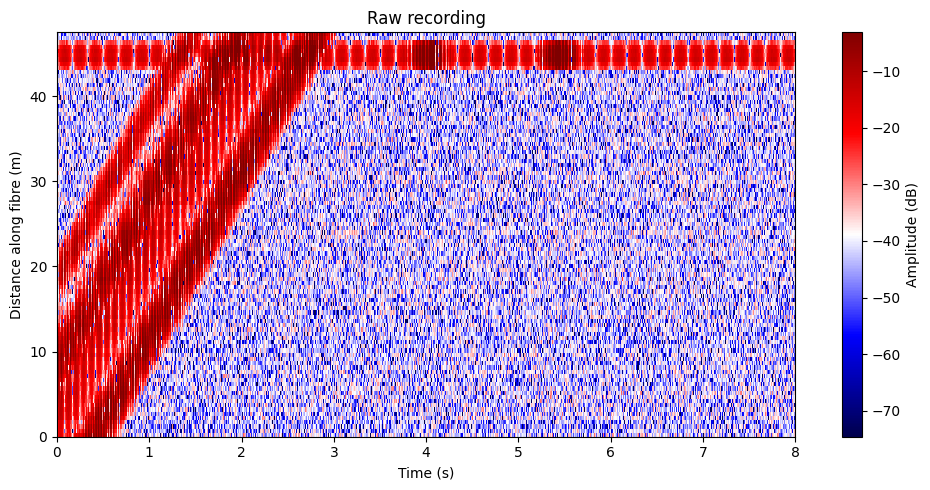

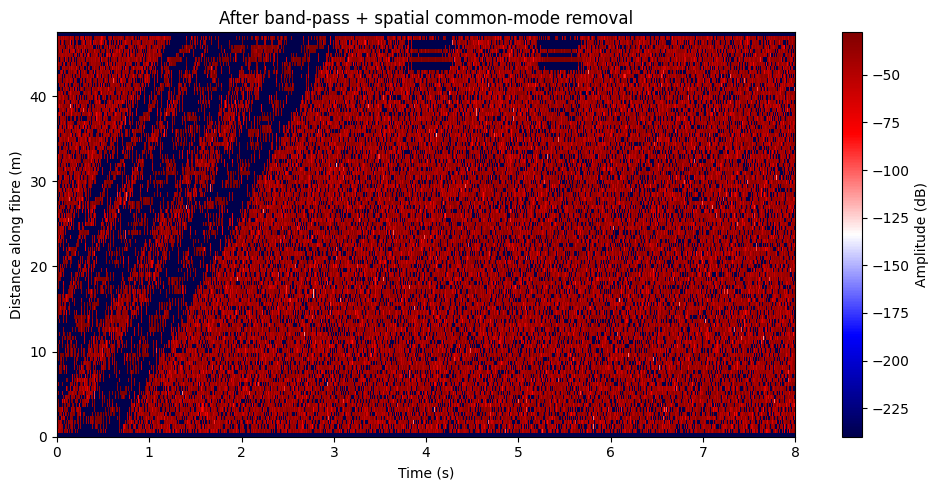

In [3]:
fig, ax = plot_waterfall(
    recording,
    sampling_rate_hz=sampling_rate_hz,
    channel_spacing_m=channel_spacing_m,
    to_db=True,
    title="Raw recording",
)
plt.show()

fig, ax = plot_waterfall(
    cleaned,
    sampling_rate_hz=sampling_rate_hz,
    channel_spacing_m=channel_spacing_m,
    to_db=True,
    title="After band-pass + spatial common-mode removal",
)
plt.show()


## 2. STFT 时频分析

选择能量最强的通道，计算其短时傅里叶变换。`stft_feature` 默认返回 dB
幅度，频率轴单位为 Hz，时间轴单位为秒。


Selected channel: 89


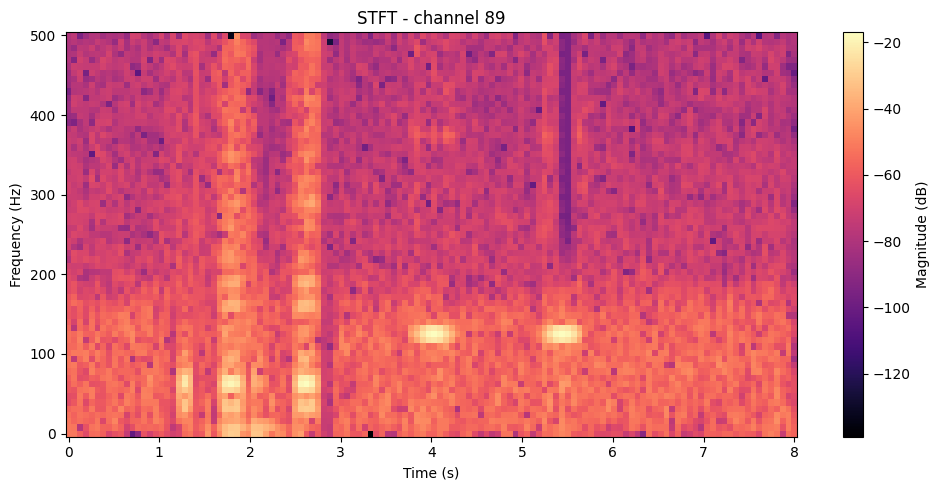

In [4]:
channel_rms = np.sqrt(np.mean(cleaned ** 2, axis=1))
selected_channel = int(np.argmax(channel_rms))
print(f"Selected channel: {selected_channel}")

nperseg = max(8, min(128, cleaned.shape[1]))
frequencies, times, magnitude = stft_feature(
    cleaned,
    sampling_rate_hz=sampling_rate_hz,
    nperseg=nperseg,
    noverlap=nperseg // 2,
    to_db=True,
    channel=selected_channel,
)
fig, ax = plot_spectrogram(
    frequencies,
    times,
    magnitude,
    title=f"STFT - channel {selected_channel}",
)
plt.show()


## 3. 小波包频带能量

小波包特征按通道归一化，可作为统计基线或异常分类器的输入。


Wavelet packet feature shape: (96, 8)


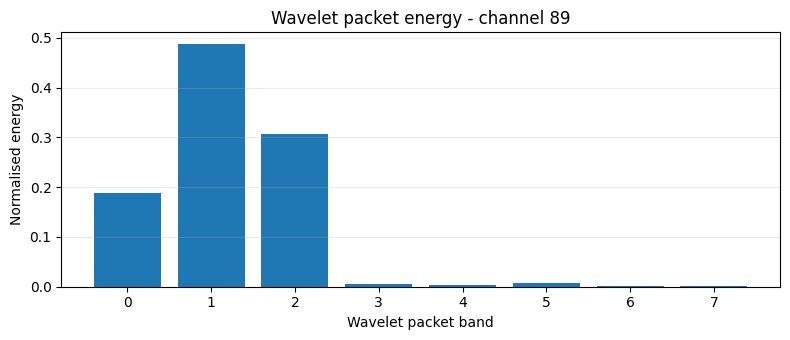

In [5]:
wavelet_energy = wavelet_packet_features(
    cleaned,
    wavelet="db4",
    level=3,
    normalize=True,
)
print("Wavelet packet feature shape:", wavelet_energy.shape)

band_index = np.arange(wavelet_energy.shape[1])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(band_index, wavelet_energy[selected_channel])
ax.set_xlabel("Wavelet packet band")
ax.set_ylabel("Normalised energy")
ax.set_title(f"Wavelet packet energy - channel {selected_channel}")
ax.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 说明

- 如果处理的是长记录，可按 `time_window_tw` 分帧后再做 STFT，以获得更稳定的
  时频统计。
- 空间共模窗口 `Cw` 越大，抑制共模噪声越强，但也可能削弱空间局部性；需要
  根据通道间距和异常尺度调节。
- 特征提取与模型输入均为相对路径，可直接在脚本中复用这些函数。
